Billy York


2/13/26

# Exploring the Rating Data

In [1]:
import polars as pl
import seaborn as sns

## Downloading the Data

In [2]:
movie_lens = pl.read_ipc('movielens_25m.feather', memory_map=False)
netflix_prize = pl.read_ipc('netflix_prize.feather', memory_map=False)
yahoo = pl.read_ipc('yahoo_r2_songs.subsample.feather', memory_map=False)
bgg = pl.read_ipc('boardgamegeek.feather', memory_map=False)

## Exploring the Data

## MovieLens

In [3]:
movie_lens.head()

item_id,user_id,rating,__index_level_0__
i64,i64,f64,i64
296,1,5.0,0
306,1,3.5,1
307,1,5.0,2
665,1,5.0,3
899,1,3.5,4


In [4]:
movie_lens_num_user = movie_lens.get_column('user_id').n_unique()
movie_lens_num_prod = movie_lens.get_column('item_id').n_unique()
movie_lens_num_rate = movie_lens.n_unique()
print(f'Number of Users: {movie_lens_num_user}')
print(f'Number of Products: {movie_lens_num_prod}')
print(f'Number of Ratings: {movie_lens_num_rate}')
print(f'Density: {movie_lens_num_rate / (movie_lens_num_user * movie_lens_num_prod)}')

Number of Users: 162541
Number of Products: 24330
Number of Ratings: 24890583
Density: 0.006294047740632277


[Text(0.5, 1.0, 'MovieLens Ratings Per Item')]

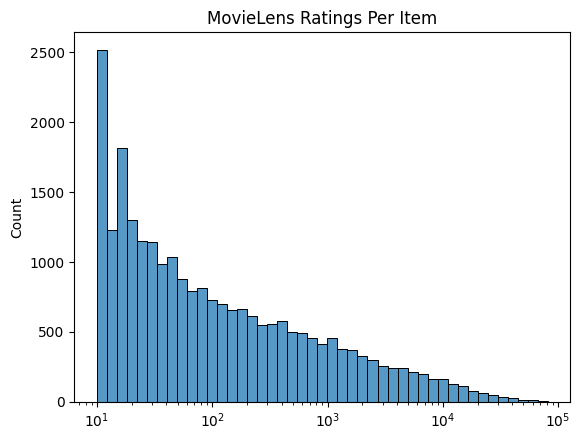

In [5]:
movie_lens_rate_per_item = movie_lens.group_by('item_id').agg(num_ratings=pl.col('user_id').n_unique())
sns.histplot(data=movie_lens_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="MovieLens Ratings Per Item")

[Text(0.5, 1.0, 'MovieLens Ratings Per User')]

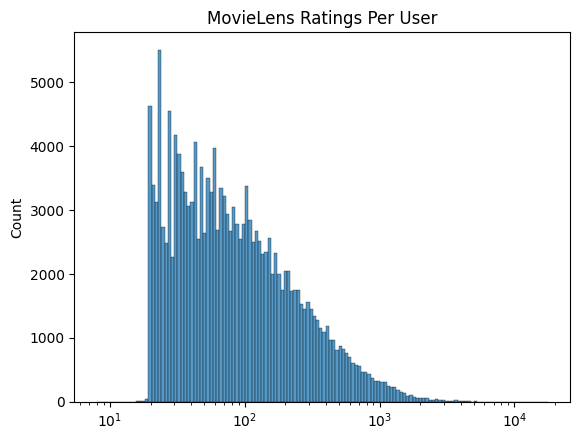

In [6]:
movie_lens_rate_per_item = movie_lens.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=movie_lens_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="MovieLens Ratings Per User")

[Text(0.5, 1.0, 'MovieLens Ratings Distribution')]

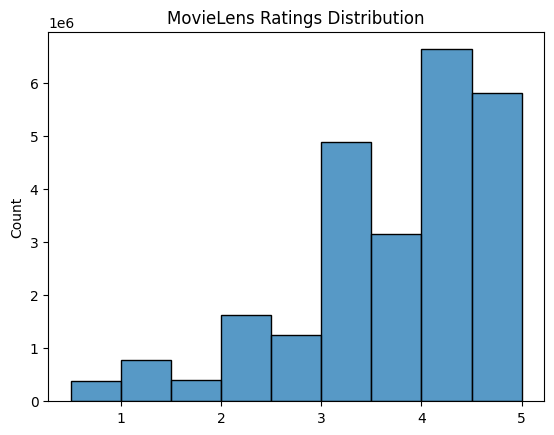

In [7]:
sns.histplot(data=movie_lens['rating'], bins=[0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]).set(title="MovieLens Ratings Distribution")

## Netflix Prize

In [8]:
netflix_prize.head()

item_id,user_id,rating
i64,i64,i64
1,1488844,3
1,822109,5
1,885013,4
1,30878,4
1,823519,3


In [9]:
netflix_prize_num_user = netflix_prize.get_column('user_id').n_unique()
netflix_prize_num_prod = netflix_prize.get_column('item_id').n_unique()
netflix_prize_num_rate = netflix_prize.n_unique()
print(f'Number of Users: {netflix_prize_num_user}')
print(f'Number of Products: {netflix_prize_num_prod}')
print(f'Number of Ratings: {netflix_prize_num_rate}')
print(f'Density: {netflix_prize_num_rate / (netflix_prize_num_user * netflix_prize_num_prod)}')

Number of Users: 478018
Number of Products: 9210
Number of Ratings: 51031355
Density: 0.011591328642583701


[Text(0.5, 1.0, 'Netflix Ratings Per Item')]

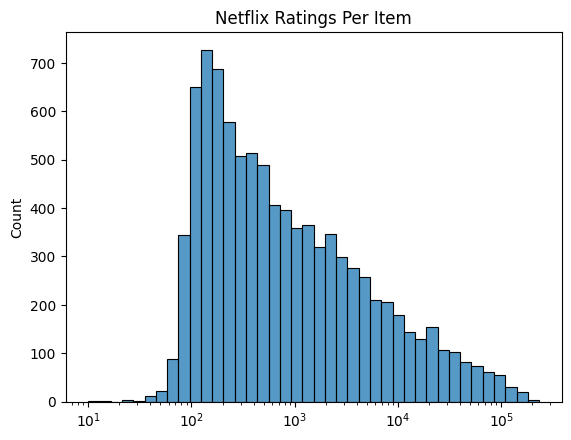

In [10]:
netflix_prize_rate_per_item = netflix_prize.group_by('item_id').agg(num_ratings=pl.col('user_id').n_unique())
sns.histplot(data=netflix_prize_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="Netflix Ratings Per Item")

[Text(0.5, 1.0, 'Netflix Ratings Per User')]

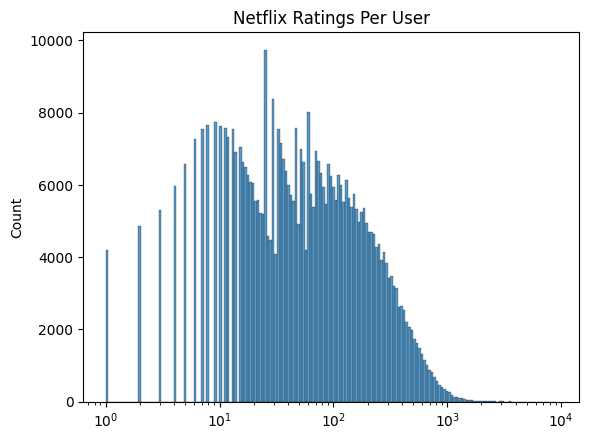

In [11]:
netflix_prize_rate_per_item = netflix_prize.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=netflix_prize_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="Netflix Ratings Per User")

[Text(0.5, 1.0, 'Netflix Ratings Distribution')]

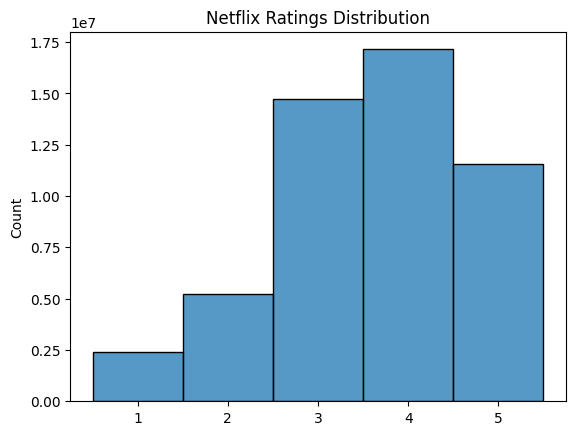

In [12]:
sns.histplot(data=netflix_prize['rating'], discrete=True, bins=[1, 2, 3, 4, 5]).set(title="Netflix Ratings Distribution")

## Yahoo! Music R2

In [13]:
yahoo.head()

item_id,user_id,rating
i64,i64,i64
166,0,5
2245,0,4
3637,0,4
5580,0,4
5859,0,4


In [14]:
yahoo_num_user = yahoo.get_column('user_id').n_unique()
yahoo_num_prod = yahoo.get_column('item_id').n_unique()
yahoo_num_rate = yahoo.n_unique()
print(f'Number of Users: {yahoo_num_user}')
print(f'Number of Products: {yahoo_num_prod}')
print(f'Number of Ratings: {yahoo_num_rate}')
print(f'Density: {yahoo_num_rate / (yahoo_num_user * yahoo_num_prod)}')

Number of Users: 200000
Number of Products: 136736
Number of Ratings: 76344627
Density: 0.002791679842908963


[Text(0.5, 1.0, 'Yahoo! Ratings Per Item')]

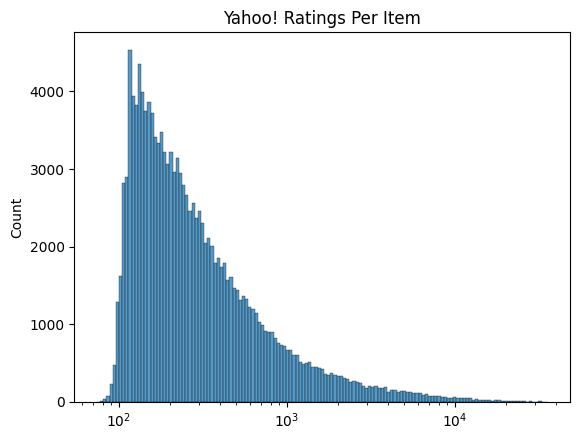

In [15]:
yahoo_rate_per_item = yahoo.group_by('item_id').agg(num_ratings=pl.col('user_id').n_unique())
sns.histplot(data=yahoo_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="Yahoo! Ratings Per Item")

[Text(0.5, 1.0, 'Yahoo! Ratings Per User')]

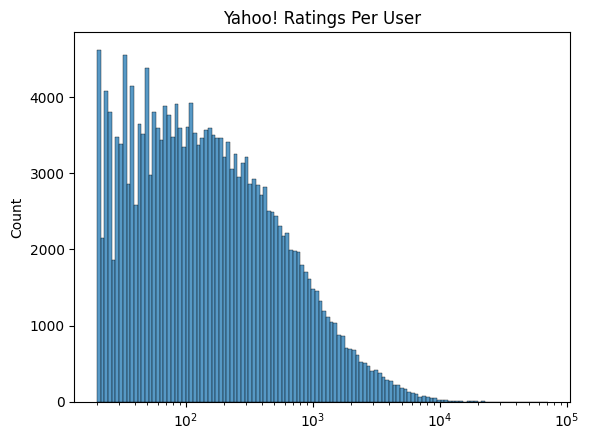

In [16]:
yahoo_rate_per_item = yahoo.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=yahoo_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="Yahoo! Ratings Per User")

[Text(0.5, 1.0, 'Yahoo! Ratings Distribution')]

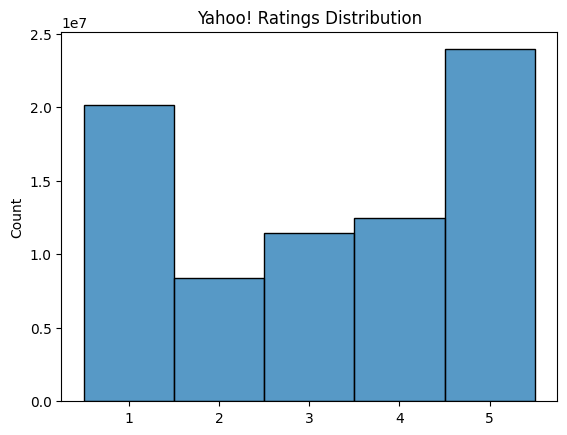

In [17]:
sns.histplot(data=yahoo['rating'], discrete=True, bins=[1, 2, 3, 4, 5, 6]).set(title="Yahoo! Ratings Distribution")

## BoardGameGeek

In [18]:
bgg.head()

item_id,user_id,rating
i64,str,f64
213788,"""Tonydorrf""",8.0
213788,"""tachyon14k""",8.0
213788,"""Ungotter""",8.0
213788,"""brainlocki3""",8.0
213788,"""PPMP""",8.0


In [19]:
bgg_num_user = bgg.get_column('user_id').n_unique()
bgg_num_prod = bgg.get_column('item_id').n_unique()
bgg_num_rate = bgg.n_unique()
print(f'Number of Users: {bgg_num_user}')
print(f'Number of Products: {bgg_num_prod}')
print(f'Number of Ratings: {bgg_num_rate}')
print(f'Density: {bgg_num_rate / (bgg_num_user * bgg_num_prod)}')

Number of Users: 411375
Number of Products: 21925
Number of Ratings: 18942215
Density: 0.002100164264032344


[Text(0.5, 1.0, 'BGG Ratings Per Item')]

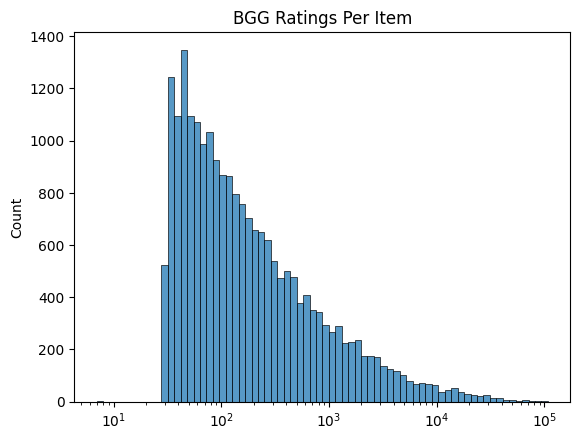

In [20]:
bgg_rate_per_item = bgg.group_by('item_id').agg(num_ratings=pl.col('user_id').n_unique())
sns.histplot(data=bgg_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="BGG Ratings Per Item")

[Text(0.5, 1.0, 'BGG Ratings Per User')]

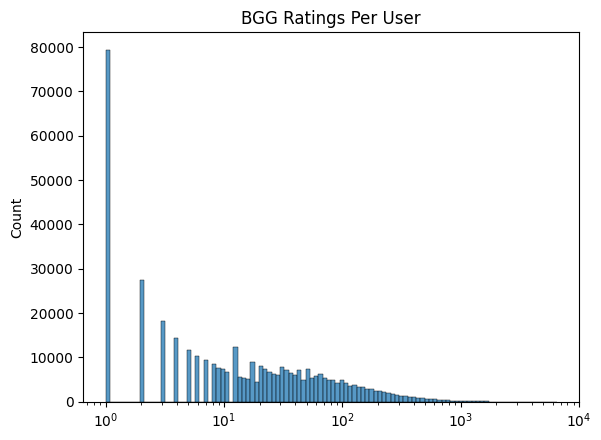

In [21]:
bgg_rate_per_item = bgg.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=bgg_rate_per_item['num_ratings'], log_scale=(True, False)).set(title="BGG Ratings Per User")

[Text(0.5, 1.0, 'BGG Ratings Distribution')]

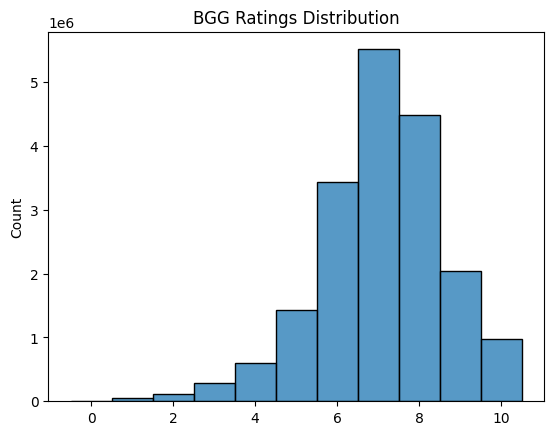

In [22]:
sns.histplot(data=bgg['rating'], discrete=True, bins=[0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5]).set(title="BGG Ratings Distribution")